In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, brier_score_loss

from category_encoders import CatBoostEncoder


In [2]:
DATA_PATH = "data_processed/ball_by_ball_canonical.csv"

df = pd.read_csv(DATA_PATH, parse_dates=["date"])



joining winner from other csv winner

In [3]:
import pandas as pd

BALL_PATH = "data_processed/ball_by_ball_canonical.csv"
MATCH_PATH = "data_processed/match_master_clean_mergedwithclimate_teamnormalized.csv"

df_ball = pd.read_csv(BALL_PATH, parse_dates=["date"])
df_match = pd.read_csv(MATCH_PATH, parse_dates=["date"])

df_match_winner = df_match[["match_id", "winner"]].copy()

df_ball = df_ball.merge(
    df_match_winner,
    on="match_id",
    how="left"
)

df_model = df_ball[
    (df_ball["is_second_innings"] == 1) &
    (df_ball["has_elo"] == True) &
    (df_ball["winner"].notna())
].copy()


df_model["target"] = (
    df_model["batting_team"] == df_model["winner"]
).astype(int)


distribution

In [4]:
df_model["target"].value_counts(normalize=True)


target
1    0.501456
0    0.498544
Name: proportion, dtype: float64

sanity check

In [5]:
end_balls = (
    df_model
    .sort_values(["match_id", "over", "ball"])
    .groupby("match_id")
    .tail(1)
)

(end_balls["target"] == 1).mean()


np.float64(0.5244779185210544)

spikes on first ball

In [6]:
# df_model.groupby("balls_remaining")["target"].mean().head(10)
df_model.groupby("balls_remaining")["target"].mean().tail(10)


balls_remaining
111    0.526177
112    0.523943
113    0.524574
114    0.524445
115    0.525334
116    0.522577
117    0.523676
118    0.528033
119    0.524910
120    0.625641
Name: target, dtype: float64

spikes on last ball

In [7]:
df_model.groupby("balls_remaining")["target"].mean().head(10)
# df_model.groupby("balls_remaining")["target"].mean().tail(10)


balls_remaining
0    0.088594
1    0.153032
2    0.207836
3    0.247674
4    0.290785
5    0.326762
6    0.352923
7    0.374479
8    0.391896
9    0.404890
Name: target, dtype: float64

remove first and last balls

In [8]:
df_model = df_model[
    (df_model["balls_remaining"] > 0) &
    (df_model["required_run_rate"].notna()) &
    (df_model["current_run_rate"].notna())
].copy()


In [10]:
df_model.groupby("balls_remaining")["target"].mean().head(10)
# df_model.groupby("balls_remaining")["target"].mean().tail(10)


balls_remaining
1     0.153032
2     0.207836
3     0.247674
4     0.290785
5     0.326762
6     0.352923
7     0.374479
8     0.391896
9     0.404890
10    0.418832
Name: target, dtype: float64

In [11]:
NUMERIC_FEATURES = [
    "runs_remaining",
    "balls_remaining",
    "wickets_lost",
    "current_run_rate",
    "required_run_rate",
    "req_per_ball",
    "rr_diff",
    "batting_elo",
    "bowling_elo",
    "elo_diff",
    "phase_powerplay",
    "phase_death"
]

CATEGORICAL_FEATURES = [
    "venue",
    "league"
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


match distribution

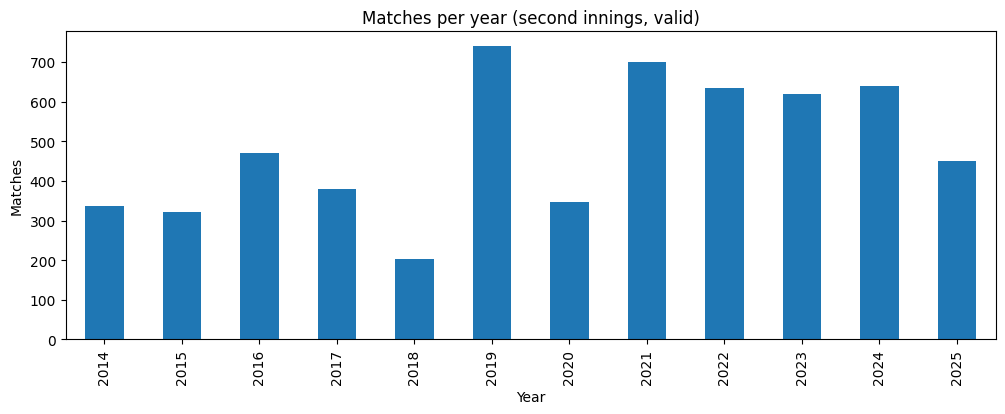

In [12]:
import matplotlib.pyplot as plt

match_counts = (
    df_model[["match_id", "date"]]
    .drop_duplicates()
    .assign(year=lambda x: x["date"].dt.year)
    .groupby("year")
    .size()
)

match_counts


match_counts.plot(kind="bar", figsize=(12,4))
plt.title("Matches per year (second innings, valid)")
plt.ylabel("Matches")
plt.xlabel("Year")
plt.show()


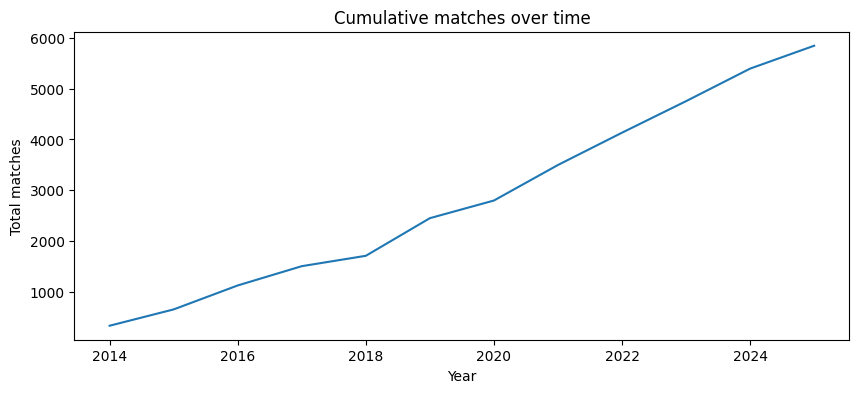

In [13]:
match_counts.cumsum().plot(figsize=(10,4))
plt.title("Cumulative matches over time")
plt.ylabel("Total matches")
plt.xlabel("Year")
plt.show()


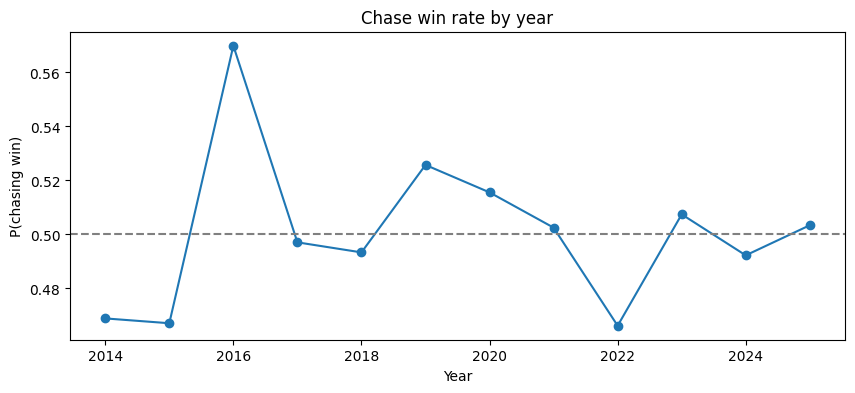

In [14]:
year_target = (
    df_model
    .assign(year=df_model["date"].dt.year)
    .groupby("year")["target"]
    .mean()
)

year_target.plot(marker="o", figsize=(10,4))
plt.axhline(0.5, linestyle="--", color="gray")
plt.title("Chase win rate by year")
plt.ylabel("P(chasing win)")
plt.xlabel("Year")
plt.show()


quantile based temporal cutoffs

In [15]:
match_dates = (
    df_model[["match_id", "date"]]
    .drop_duplicates()
    .sort_values("date")
)

train_cutoff = match_dates["date"].quantile(0.65)
val_cutoff   = match_dates["date"].quantile(0.85)

train_cutoff, val_cutoff


(Timestamp('2022-06-10 00:00:00'), Timestamp('2024-03-27 20:24:00'))

In [16]:
train_df = df_model[df_model["date"] <= train_cutoff]
val_df   = df_model[
    (df_model["date"] > train_cutoff) &
    (df_model["date"] <= val_cutoff)
]
test_df  = df_model[df_model["date"] > val_cutoff]


In [17]:
def split_summary(df, name):
    print(f"{name}")
    print(" Matches:", df["match_id"].nunique())
    print(" Balls:", len(df))
    print(" Win rate:", round(df["target"].mean(), 3))
    print()

split_summary(train_df, "TRAIN")
split_summary(val_df, "VAL")
split_summary(test_df, "TEST")


TRAIN
 Matches: 3799
 Balls: 423255
 Win rate: 0.506

VAL
 Matches: 1166
 Balls: 129249
 Win rate: 0.49

TEST
 Matches: 877
 Balls: 96745
 Win rate: 0.503



In [18]:
from category_encoders import CatBoostEncoder

encoder = CatBoostEncoder(
    cols=CATEGORICAL_FEATURES,
    random_state=42
)

X_train = train_df[FEATURES]
y_train = train_df["target"]

X_val = val_df[FEATURES]
y_val = val_df["target"]

X_test = test_df[FEATURES]
y_test = test_df["target"]

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc   = encoder.transform(X_val)
X_test_enc  = encoder.transform(X_test)


checking for nans (must not be there because of prior cleaning)

In [19]:
nan_counts = X_train_enc.isna().sum().sort_values(ascending=False)
nan_counts[nan_counts > 0]


Series([], dtype: int64)

In [20]:
def nan_summary(df, name):
    print(f"\n{name}")
    print(df.isna().sum()[df.isna().sum() > 0])

nan_summary(X_train_enc, "TRAIN")
nan_summary(X_val_enc,   "VAL")
nan_summary(X_test_enc,  "TEST")



TRAIN
Series([], dtype: int64)

VAL
Series([], dtype: int64)

TEST
Series([], dtype: int64)


In [21]:
from sklearn.linear_model import LogisticRegression

wp_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    n_jobs=-1
)

wp_model.fit(X_train_enc, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [22]:
wp_model_cal = CalibratedClassifierCV(
    wp_model,
    method="isotonic",
    cv="prefit"
)

wp_model_cal.fit(X_val_enc, y_val)


C:\Users\kathe\AppData\Roaming\Python\Python314\site-packages\sklearn\calibration.py:330: FutureWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


,estimator,"LogisticRegre...00, n_jobs=-1)"
,method,'isotonic'
,cv,'prefit'
,n_jobs,None
,ensemble,'auto'
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1


In [23]:
from sklearn.metrics import log_loss, brier_score_loss

val_probs  = wp_model_cal.predict_proba(X_val_enc)[:, 1]
test_probs = wp_model_cal.predict_proba(X_test_enc)[:, 1]

print("VAL LogLoss:", log_loss(y_val, val_probs))
print("VAL Brier:", brier_score_loss(y_val, val_probs))

print("TEST LogLoss:", log_loss(y_test, test_probs))
print("TEST Brier:", brier_score_loss(y_test, test_probs))


VAL LogLoss: 0.36380488364633967
VAL Brier: 0.11745440021950117
TEST LogLoss: 0.39813236964428167
TEST Brier: 0.12456769949221339


final model build

In [24]:
X_trval_enc = pd.concat([X_train_enc, X_val_enc])
y_trval = pd.concat([y_train, y_val])

wp_model_final = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    n_jobs=-1
)

wp_model_final.fit(X_trval_enc, y_trval)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [25]:
from sklearn.calibration import CalibratedClassifierCV

wp_model_cal_final = CalibratedClassifierCV(
    wp_model_final,
    method="isotonic",
    cv="prefit"
)

wp_model_cal_final.fit(X_val_enc, y_val)


C:\Users\kathe\AppData\Roaming\Python\Python314\site-packages\sklearn\calibration.py:330: FutureWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


,estimator,"LogisticRegre...00, n_jobs=-1)"
,method,'isotonic'
,cv,'prefit'
,n_jobs,None
,ensemble,'auto'
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1


In [27]:
df_all = df_ball.copy()

df_all = df_all[
    (df_all["is_second_innings"] == 1) &
    (df_all["has_elo"] == True)
].copy()

# CRITICAL: same semantic filter as training
df_all = df_all[
    (df_all["balls_remaining"] > 0) &
    (df_all["required_run_rate"].notna()) &
    (df_all["current_run_rate"].notna())
].copy()

X_all = df_all[FEATURES]
X_all_enc = encoder.transform(X_all)


sanity checks

In [28]:
X_all_enc.isna().sum()[X_all_enc.isna().sum() > 0]


Series([], dtype: int64)

In [29]:
(X_all_enc.isna().mean() * 100).sort_values(ascending=False).head()


runs_remaining       0.0
balls_remaining      0.0
wickets_lost         0.0
current_run_rate     0.0
required_run_rate    0.0
dtype: float64

In [30]:
df_all["win_probability"] = wp_model_cal_final.predict_proba(X_all_enc)[:, 1]


In [31]:
df_all.groupby("balls_remaining")["win_probability"].mean().tail(10)


balls_remaining
110    0.534161
111    0.533136
112    0.529802
113    0.528281
114    0.528190
115    0.527674
116    0.525726
117    0.525221
118    0.527182
119    0.523504
Name: win_probability, dtype: float64

wpa computation

In [32]:
df_all = df_all.sort_values(["match_id", "innings", "over", "ball"])

df_all["wpa"] = (
    df_all
    .groupby(["match_id", "innings"])["win_probability"]
    .diff()
    .fillna(0.0)
)


sanity check

In [33]:
df_all["wpa"].describe()


count    649249.000000
mean          0.000063
std           0.033233
min          -0.805264
25%           0.000000
50%           0.000000
75%           0.000000
max           0.960373
Name: wpa, dtype: float64

In [34]:
import joblib
from datetime import date

joblib.dump(
    {
        "model": wp_model_cal_final,
        "description": {
            "model_type": "Logistic Regression + Isotonic Calibration",
            "task": "T20 second-innings Win Probability",
            "features": FEATURES,
            "categorical_features": CATEGORICAL_FEATURES,
            "training_data": "TRAIN + VAL (time-based split)",
            "calibration_data": "VAL only",
            "boundary_handling": "Dropped terminal states and undefined-rate states",
            "evaluation": {
                "val_logloss": 0.3638,
                "val_brier": 0.1175,
                "test_logloss": 0.3981,
                "test_brier": 0.1246
            },
            "date_trained": str(date.today())
        }
    },
    "models/wp_model_t20_v1.pkl"
)

joblib.dump(
    {
        "encoder": encoder,
        "description": {
            "type": "CatBoostEncoder",
            "fitted_on": "TRAIN only",
            "categorical_features": CATEGORICAL_FEATURES
        }
    },
    "models/wp_encoder_t20_v1.pkl"
)


['models/wp_encoder_t20_v1.pkl']

In [36]:
df_all.columns.tolist()



['match_id',
 'innings',
 'over',
 'ball',
 'batting_team',
 'bowling_team',
 'batter',
 'bowler',
 'fielder',
 'runs_off_bat',
 'extras',
 'total_runs',
 'is_wicket',
 'runs_remaining',
 'balls_remaining',
 'wickets_lost',
 'current_run_rate',
 'required_run_rate',
 'req_per_ball',
 'rr_diff',
 'is_second_innings',
 'phase_powerplay',
 'phase_death',
 'date',
 'league',
 'team1',
 'team2',
 'venue',
 'city',
 'latitude',
 'longitude',
 'tavg',
 'tmax',
 'tmin',
 'rhum',
 'prcp',
 'wspd',
 'pres',
 'tsun',
 'batting_elo',
 'batting_team_matches',
 'bowling_elo',
 'bowling_team_matches',
 'elo_diff',
 'bat_first_team',
 'bat_first_flag',
 'has_elo',
 'winner',
 'win_probability',
 'wpa']

In [37]:
assert "wpa" in df_all.columns
assert "batter" in df_all.columns
assert "bowler" in df_all.columns


In [45]:
# =========================
# CONFIG
# =========================
BAT_COL = "batter"
BOWL_COL = "bowler"

MIN_BAT_BALLS = 200
MIN_BOWL_BALLS = 200

# =========================
# SAFETY CHECKS
# =========================
assert "wpa" in df_all.columns
assert BAT_COL in df_all.columns
assert BOWL_COL in df_all.columns

# =========================
# BASE COUNTS
# =========================
balls_faced = df_all.groupby(BAT_COL).size()
balls_bowled = df_all.groupby(BOWL_COL).size()

# =========================
# ABSOLUTE WPA (impact magnitude)
# =========================
df_all["abs_wpa"] = df_all["wpa"].abs()

# =========================
# ---------- BATTING WPA ----------
# =========================
batting_wpa_total = df_all.groupby(BAT_COL)["wpa"].sum()
batting_abs_wpa_total = df_all.groupby(BAT_COL)["abs_wpa"].sum()

batting_wpa_per_100 = batting_wpa_total / balls_faced * 100
batting_abs_wpa_per_100 = batting_abs_wpa_total / balls_faced * 100

valid_batters = balls_faced[balls_faced >= MIN_BAT_BALLS].index

batting_summary = (
    pd.DataFrame({
        "balls_faced": balls_faced.loc[valid_batters],
        "total_wpa": batting_wpa_total.loc[valid_batters],
        "wpa_per_100_balls": batting_wpa_per_100.loc[valid_batters],
        "absolute_wpa": batting_abs_wpa_total.loc[valid_batters],
        "absolute_wpa_per_100": batting_abs_wpa_per_100.loc[valid_batters],
    })
    .sort_values("total_wpa", ascending=False)
)

# =========================
# ---------- BOWLING WPA ----------
# (negative WPA = GOOD)
# =========================
bowling_wpa_total = df_all.groupby(BOWL_COL)["wpa"].sum()
bowling_abs_wpa_total = df_all.groupby(BOWL_COL)["abs_wpa"].sum()

bowling_wpa_per_100 = bowling_wpa_total / balls_bowled * 100
bowling_abs_wpa_per_100 = bowling_abs_wpa_total / balls_bowled * 100

valid_bowlers = balls_bowled[balls_bowled >= MIN_BOWL_BALLS].index

bowling_summary = (
    pd.DataFrame({
        "balls_bowled": balls_bowled.loc[valid_bowlers],
        "total_wpa": bowling_wpa_total.loc[valid_bowlers],
        "wpa_per_100_balls": bowling_wpa_per_100.loc[valid_bowlers],
        "absolute_wpa": bowling_abs_wpa_total.loc[valid_bowlers],
        "absolute_wpa_per_100": bowling_abs_wpa_per_100.loc[valid_bowlers],
    })
    .sort_values("total_wpa")  # more negative = better
)

# =========================
# PREVIEWS
# =========================
print("TOP BATTERS BY TOTAL WPA")
display(batting_summary.head(15))

print("\nTOP BATTERS BY WPA / 100 BALLS")
display(batting_summary.sort_values("wpa_per_100_balls", ascending=False).head(15))

print("\nTOP BOWLERS BY TOTAL WPA (MOST NEGATIVE = BEST)")
display(bowling_summary.head(15))

print("\nTOP BOWLERS BY WPA / 100 BALLS (MOST NEGATIVE = BEST)")
display(bowling_summary.sort_values("wpa_per_100_balls").head(15))


TOP BATTERS BY TOTAL WPA


,balls_faced,total_wpa,wpa_per_100_balls,absolute_wpa,absolute_wpa_per_100
batter,,,,,
AD Hales,4586,11.022656,0.240354,66.091888,1.441166
CH Gayle,2868,8.214987,0.286436,45.216181,1.576575
JM Vince,4203,7.749317,0.184376,53.089829,1.263141
E Lewis,1916,7.668337,0.400226,30.000780,1.565803
GJ Maxwell,2974,7.087060,0.238301,40.457814,1.360384
CA Lynn,2508,6.971165,0.277957,38.899426,1.551014
AJ Finch,3100,6.555849,0.211479,41.421636,1.336182
V Kohli,3074,6.360831,0.206924,34.169879,1.111577
N Pooran,3024,6.116756,0.202274,42.143415,1.393631



TOP BATTERS BY WPA / 100 BALLS


,balls_faced,total_wpa,wpa_per_100_balls,absolute_wpa,absolute_wpa_per_100
batter,,,,,
GH Dockrell,256,1.431113,0.559029,2.883166,1.126237
D Ferreira,428,2.192805,0.512338,9.865767,2.305086
EA Brookes,206,1.015784,0.493099,4.150136,2.014629
Shahid Afridi,595,2.853438,0.479569,15.109023,2.539332
DR Sams,610,2.719935,0.445891,14.550914,2.385396
S Muthusamy,281,1.152516,0.410148,4.867998,1.732384
JP Duminy,873,3.511419,0.402224,11.506076,1.317993
E Lewis,1916,7.668337,0.400226,30.000780,1.565803
JW Hastings,216,0.856246,0.396410,3.768180,1.744528



TOP BOWLERS BY TOTAL WPA (MOST NEGATIVE = BEST)


,balls_bowled,total_wpa,wpa_per_100_balls,absolute_wpa,absolute_wpa_per_100
bowler,,,,,
SP Narine,4499,-11.405882,-0.253520,48.565454,1.079472
Rashid Khan,3759,-7.776876,-0.206887,48.334775,1.285841
Imran Tahir,3330,-5.989194,-0.179856,37.904275,1.138267
Wahab Riaz,2290,-4.420227,-0.193023,38.004080,1.659567
HF Gurney,1128,-4.195705,-0.371960,21.300509,1.888343
PM Siddle,1317,-4.039515,-0.306721,19.707298,1.496378
JJ Bumrah,2220,-4.007605,-0.180523,30.884781,1.391206
Mustafizur Rahman,2313,-3.535390,-0.152849,30.676408,1.326261
Mohammad Amir,2755,-3.490709,-0.126704,49.394589,1.792907



TOP BOWLERS BY WPA / 100 BALLS (MOST NEGATIVE = BEST)


,balls_bowled,total_wpa,wpa_per_100_balls,absolute_wpa,absolute_wpa_per_100
bowler,,,,,
Sayan Ghosh,212,-1.493821,-0.704633,4.540327,2.141663
RO Gordon,288,-1.353300,-0.469896,4.669163,1.621237
Yuvraj Singh,307,-1.305637,-0.425289,3.776775,1.230220
Ravi Teja,206,-0.852685,-0.413925,2.652032,1.287394
RJ Peterson,469,-1.908625,-0.406956,7.015208,1.495780
KK Cooper,742,-2.817714,-0.379746,13.111571,1.767058
Taijul Islam,493,-1.835476,-0.372308,6.833337,1.386072
HF Gurney,1128,-4.195705,-0.371960,21.300509,1.888343
Mohammad Sami,856,-3.098252,-0.361945,18.688850,2.183277


function for finding wpa tables (from start data , league type etc)

In [46]:
def wpa_tables(
    df,
    start_date,
    league="all",
    bat_col="batter",
    bowl_col="bowler",
    min_bat_balls=200,
    min_bowl_balls=200
):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    start_date = pd.to_datetime(start_date)

    df = df[df["date"] >= start_date]

    if league != "all":
        df = df[df["league"] == league]

    balls_faced = df.groupby(bat_col).size()
    balls_bowled = df.groupby(bowl_col).size()

    bat_wpa = df.groupby(bat_col)["wpa"].sum()
    bat_abs = df.groupby(bat_col)["abs_wpa"].sum()

    bowl_wpa = df.groupby(bowl_col)["wpa"].sum()
    bowl_abs = df.groupby(bowl_col)["abs_wpa"].sum()

    bat_wpa_100 = bat_wpa / balls_faced * 100
    bat_abs_100 = bat_abs / balls_faced * 100

    bowl_wpa_100 = bowl_wpa / balls_bowled * 100
    bowl_abs_100 = bowl_abs / balls_bowled * 100

    valid_bat = balls_faced[balls_faced >= min_bat_balls].index
    valid_bowl = balls_bowled[balls_bowled >= min_bowl_balls].index

    batting = pd.DataFrame({
        "balls_faced": balls_faced.loc[valid_bat],
        "total_wpa": bat_wpa.loc[valid_bat],
        "wpa_per_100": bat_wpa_100.loc[valid_bat],
        "absolute_wpa": bat_abs.loc[valid_bat],
        "absolute_wpa_per_100": bat_abs_100.loc[valid_bat],
    }).sort_values("total_wpa", ascending=False)

    bowling = pd.DataFrame({
        "balls_bowled": balls_bowled.loc[valid_bowl],
        "total_wpa": bowl_wpa.loc[valid_bowl],
        "wpa_per_100": bowl_wpa_100.loc[valid_bowl],
        "absolute_wpa": bowl_abs.loc[valid_bowl],
        "absolute_wpa_per_100": bowl_abs_100.loc[valid_bowl],
    }).sort_values("total_wpa")

    return batting, bowling


In [67]:
bat_ipl, bowl_ipl = wpa_tables(
    df_all,
    start_date="2021-01-01",
    league="International",
    min_bat_balls=100,
    min_bowl_balls=100
)


In [68]:
display(bat_ipl.head(25))
display(bowl_ipl.head(25))


,balls_faced,total_wpa,wpa_per_100,absolute_wpa,absolute_wpa_per_100
batter,,,,,
MD Shanaka,343,1.918638,0.559370,5.546765,1.617133
SA Yadav,545,1.886724,0.346188,6.912692,1.268384
E Lewis,313,1.831445,0.585126,5.653596,1.806261
Mohammad Rizwan,1126,1.818787,0.161526,11.733145,1.042020
V Kohli,227,1.650557,0.727117,4.008497,1.765858
RR Hendricks,740,1.572788,0.212539,9.915305,1.339906
BKG Mendis,483,1.533216,0.317436,4.755911,0.984661
GH Dockrell,256,1.431113,0.559029,2.883166,1.126237
DA Warner,448,1.252044,0.279474,4.937044,1.102019


,balls_bowled,total_wpa,wpa_per_100,absolute_wpa,absolute_wpa_per_100
bowler,,,,,
Mustafizur Rahman,465,-1.777611,-0.382282,5.367667,1.154337
T Shamsi,485,-1.663028,-0.342892,4.403983,0.908038
Shakib Al Hasan,392,-1.223245,-0.312052,5.464614,1.394034
PWH de Silva,599,-1.100133,-0.183662,5.399919,0.901489
R Ngarava,482,-1.029144,-0.213515,7.856481,1.629975
AS Joseph,452,-0.998423,-0.220890,7.408915,1.639141
MR Adair,320,-0.957055,-0.299080,3.854386,1.204496
AR Patel,605,-0.944855,-0.156174,5.377254,0.888802
MJ Henry,198,-0.925239,-0.467292,3.845877,1.942362


master wpa csv

In [60]:
# =========================
# CONFIG
# =========================
BAT_COL = "batter"
BOWL_COL = "bowler"

MIN_BAT_BALLS = 200
MIN_BOWL_BALLS = 200

# =========================
# BASE COUNTS
# =========================
balls_faced = df_all.groupby(BAT_COL).size()
balls_bowled = df_all.groupby(BOWL_COL).size()

# =========================
# ABS WPA
# =========================
df_all["abs_wpa"] = df_all["wpa"].abs()

# =========================
# BATTING METRICS
# =========================
bat_wpa = df_all.groupby(BAT_COL)["wpa"].sum()
bat_abs = df_all.groupby(BAT_COL)["abs_wpa"].sum()

bat_wpa_100 = bat_wpa / balls_faced * 100
bat_abs_100 = bat_abs / balls_faced * 100

bat_df = pd.DataFrame({
    "balls_faced": balls_faced,
    "batting_wpa_total": bat_wpa,
    "batting_wpa_per_100": bat_wpa_100,
    "batting_abs_wpa": bat_abs,
    "batting_abs_wpa_per_100": bat_abs_100
})

bat_df = bat_df[bat_df["balls_faced"] >= MIN_BAT_BALLS]

# =========================
# BOWLING METRICS
# =========================
bowl_wpa = df_all.groupby(BOWL_COL)["wpa"].sum()
bowl_abs = df_all.groupby(BOWL_COL)["abs_wpa"].sum()

bowl_wpa_100 = bowl_wpa / balls_bowled * 100
bowl_abs_100 = bowl_abs / balls_bowled * 100

bowl_df = pd.DataFrame({
    "balls_bowled": balls_bowled,
    "bowling_wpa_total": bowl_wpa,
    "bowling_wpa_per_100": bowl_wpa_100,
    "bowling_abs_wpa": bowl_abs,
    "bowling_abs_wpa_per_100": bowl_abs_100
})

bowl_df = bowl_df[bowl_df["balls_bowled"] >= MIN_BOWL_BALLS]

# =========================
# CONSOLIDATE (OUTER JOIN)
# =========================
player_master = (
    bat_df
    .merge(
        bowl_df,
        left_index=True,
        right_index=True,
        how="outer"
    )
)

# =========================
# CLEANUP
# =========================
player_master = player_master.fillna(0)

# Optional: total impact metric
player_master["total_abs_wpa"] = (
    player_master["batting_abs_wpa"] +
    player_master["bowling_abs_wpa"]
)

# Sort by overall impact
player_master = player_master.sort_values(
    "total_abs_wpa",
    ascending=False
)

player_master.head(20)

player_master.reset_index().rename(
    columns={"index": "player"}
).to_csv(
    "outputs/player_wpa_master_all_time.csv",
    index=False
)


In [69]:
df_all.columns


Index(['match_id', 'innings', 'over', 'ball', 'batting_team', 'bowling_team',
       'batter', 'bowler', 'fielder', 'runs_off_bat', 'extras', 'total_runs',
       'is_wicket', 'runs_remaining', 'balls_remaining', 'wickets_lost',
       'current_run_rate', 'required_run_rate', 'req_per_ball', 'rr_diff',
       'is_second_innings', 'phase_powerplay', 'phase_death', 'date', 'league',
       'team1', 'team2', 'venue', 'city', 'latitude', 'longitude', 'tavg',
       'tmax', 'tmin', 'rhum', 'prcp', 'wspd', 'pres', 'tsun', 'batting_elo',
       'batting_team_matches', 'bowling_elo', 'bowling_team_matches',
       'elo_diff', 'bat_first_team', 'bat_first_flag', 'has_elo', 'winner',
       'win_probability', 'wpa', 'abs_wpa'],
      dtype='object')

In [ ]:
df_all = df_all.sort_values(
    ["match_id", "innings", "over", "ball"]
).copy()

df_all["wp_after_ball"] = (
    df_all
    .groupby(["match_id", "innings"])["win_probability"]
    .shift(-1)
)

df_all["wpa"] = df_all["wp_after_ball"] - df_all["win_probability"]
df_all["abs_wpa"] = df_all["wpa"].abs()

df_all = df_all.dropna(subset=["wp_after_ball"])


In [71]:
df_all["wpa"].mean(), df_all["wpa"].median()


(np.float64(6.310452174692649e-05), np.float64(0.0))

In [72]:
df_all.groupby("balls_remaining")["abs_wpa"].mean().tail(10)


balls_remaining
110    0.014670
111    0.015577
112    0.016472
113    0.015980
114    0.015890
115    0.018241
116    0.019581
117    0.023175
118    0.027638
119    0.038723
Name: abs_wpa, dtype: float64

In [73]:
OUT_CSV = "outputs/ball_by_ball_wp_wpa_t20.csv"
df_all.to_csv(OUT_CSV, index=False)
